# CREDIT CARD FRAUD PATTERN EXPLORER
**EC2023E Foundations of Data Science | NIT Calicut | EC-02, Group 18**  
**Krishna Anilraj (B250945EC) & Krishna Kumar Jha (B250946EC)**

**Aim:** Study the patterns associated with fraudulent credit-card transactions using **Pandas, SQLite SQL, Matplotlib and Seaborn**. This is a basic **exploratory data analysis** project. **No machine learning model is used.**

**Dataset:** `credit_card_fraud_10k.csv` (synthetic data) — [Kaggle source](https://www.kaggle.com/datasets/miadul/credit-card-fraud-detection-dataset).


## 1. Setup


In [2]:
%pip install jupysql pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from IPython.display import display

## 2. Load and inspect the CSV
Class topics: `pd.read_csv()`, `head()`, `shape`, `info()`, `describe()` and `value_counts()`.

In [4]:
df = pd.read_csv("credit_card_fraud_10k.csv")
print("Rows and columns:", df.shape)
print("First five rows:")
display(df.head())

Rows and columns: (10000, 10)
First five rows:


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [5]:
df.info()
print("Summary of numerical columns:")
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  object 
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), object(1)
memory usage: 781.4+ KB
Summary of numerical columns:


,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,175.949849,11.593300,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000
max,10000.00000,1471.040000,23.000000,1.000000,1.000000,99.000000,9.000000,69.000000,1.000000


## 3. Data cleaning
As taught in the Data Cleaning slides: examine missing values and duplicate records.

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df["transaction_id"].duplicated().sum())

Missing values in each column:
transaction_id         0
amount                 0
transaction_hour       0
merchant_category      0
foreign_transaction    0
location_mismatch      0
device_trust_score     0
velocity_last_24h      0
cardholder_age         0
is_fraud               0
dtype: int64
Duplicate rows: 0
Duplicate transaction IDs: 0


In [7]:
# These steps use the functions taught in class.
df = df.dropna()
df = df.drop_duplicates()
print("Rows after cleaning:", len(df))

print("Invalid fraud labels:", len(df[~df["is_fraud"].isin([0, 1])]))
print("Invalid transaction hours:", len(df[(df["transaction_hour"] < 0) | (df["transaction_hour"] > 23)]))

Rows after cleaning: 10000
Invalid fraud labels: 0
Invalid transaction hours: 0


### Check amount outliers using IQR
The class material shows `quantile()` and the **1.5 × IQR** rule. Large amounts might be important in a fraud dataset, so we **identify but retain** them.

In [8]:
Q1 = df["amount"].quantile(0.25)
Q3 = df["amount"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
outliers = df[df["amount"] > upper_limit]
print("Upper IQR limit:", round(upper_limit, 2))
print("Possible high amount outliers:", len(outliers))
print("These rows are kept for the analysis.")

Upper IQR limit: 529.84
Possible high amount outliers: 501
These rows are kept for the analysis.


## 4. SQLite database (3NF)

The course requires **multiple related tables** with primary and foreign keys. Here we use:

| Table | Purpose | Key |
|---|---|---|
| `merchant_categories` | Unique merchant categories | `merchant_category` (PK) |
| `transactions` | Transaction details and fraud label | `transaction_id` (PK), `merchant_category` (FK) |
| `transaction_indicators` | Flags, device trust and frequency for each transaction | `transaction_id` (PK + FK) |

This structure satisfies **3NF** under the dataset's assumed dependencies. No non-key field is repeated between the final tables. Separating the indicators is for easy organization, not a mandatory 3NF step. We do not invent a cardholder ID (none exists in the CSV).

**Why is `transactions_raw` used?** It is just a temporary table for importing the CSV. We create it, populate the three final tables using SQL and then remove it. This avoids typing 10,000 individual `INSERT` statements.

### 4.1 Connect to SQLite from within Jupyter
These SQL magic commands are shown in **Lab 9**.

In [9]:
%load_ext sql

In [10]:
%sql sqlite:///creditcardfraud.db

Connecting to 'sqlite:///creditcardfraud.db'

### 4.2 Import the CSV into a temporary SQL table
Only this bulk-import step uses `df.to_sql()` with Python's `sqlite3` connection. All database creation and analysis queries below use **`%%sql` inside notebook cells**. The class Lab 9 also introduces `sqlite3.connect()`.

This import step is the smallest practical bridge between the CSV and our SQLite tables.

In [11]:
connection = sqlite3.connect("creditcardfraud.db")
df.to_sql("transactions_raw", connection, if_exists="replace", index=False)
connection.close()
print("Temporary transactions_raw table imported from CSV.")

Temporary transactions_raw table imported from CSV.


### 4.3 Create the three related tables
`CREATE TABLE`, data types, `PRIMARY KEY`, and `FOREIGN KEY`.

In [12]:
%%sql
DROP TABLE IF EXISTS transaction_indicators;
DROP TABLE IF EXISTS transactions;
DROP TABLE IF EXISTS merchant_categories;

CREATE TABLE merchant_categories (
    merchant_category TEXT PRIMARY KEY
);

CREATE TABLE transactions (
    transaction_id INTEGER PRIMARY KEY,
    amount REAL,
    transaction_hour INTEGER,
    merchant_category TEXT,
    cardholder_age INTEGER,
    is_fraud INTEGER,
    FOREIGN KEY (merchant_category) REFERENCES merchant_categories(merchant_category)
);

CREATE TABLE transaction_indicators (
    transaction_id INTEGER PRIMARY KEY,
    foreign_transaction INTEGER,
    location_mismatch INTEGER,
    device_trust_score INTEGER,
    velocity_last_24h INTEGER,
    FOREIGN KEY (transaction_id) REFERENCES transactions(transaction_id)
);

Running query in 'sqlite:///creditcardfraud.db'

++
||
++
++

### 4.4 Insert data into the final tables
This uses the basic `INSERT`, `SELECT` and `DISTINCT` ideas from SQL classes. `INSERT ... SELECT` copies multiple CSV rows at once; it replaces manually writing 10,000 `INSERT ... VALUES` statements.

In [13]:
%%sql
INSERT INTO merchant_categories
SELECT DISTINCT merchant_category FROM transactions_raw;

INSERT INTO transactions
SELECT transaction_id, amount, transaction_hour, merchant_category,
       cardholder_age, is_fraud
FROM transactions_raw;

INSERT INTO transaction_indicators
SELECT transaction_id, foreign_transaction, location_mismatch,
       device_trust_score, velocity_last_24h
FROM transactions_raw;
DROP TABLE transactions_raw;

Running query in 'sqlite:///creditcardfraud.db'

5 rows affected.

10000 rows affected.

10000 rows affected.

++
||
++
++

### 4.5 Check the tables and sample records

In [14]:
%%sql
SELECT COUNT(*) AS total_transactions FROM transactions;

Running query in 'sqlite:///creditcardfraud.db'

total_transactions
10000


In [15]:
%%sql
SELECT * FROM merchant_categories;

Running query in 'sqlite:///creditcardfraud.db'

merchant_category
Electronics
Travel
Grocery
Food
Clothing


In [16]:
%%sql
SELECT * FROM transactions LIMIT 5;

Running query in 'sqlite:///creditcardfraud.db'

transaction_id,amount,transaction_hour,merchant_category,cardholder_age,is_fraud
1,84.47,22,Electronics,40,0
2,541.82,3,Travel,64,0
3,237.01,17,Grocery,61,0
4,164.33,4,Grocery,34,0
5,30.53,15,Food,44,0


### 4.6 Basic SQL queries (as in class)
We use **`SELECT`, `WHERE`, `JOIN`, `GROUP BY`, `COUNT`, `SUM` and `AVG`**. `GROUP BY` and aggregate functions are simple extensions for summarizing fraud, similar to the Pandas `groupby()`.

In [17]:
%%sql
SELECT is_fraud, COUNT(*) AS total
FROM transactions
GROUP BY is_fraud;

Running query in 'sqlite:///creditcardfraud.db'

is_fraud,total
0,9849
1,151


In [18]:
%%sql
SELECT merchant_category, COUNT(*) AS total, SUM(is_fraud) AS fraud_count
FROM transactions
GROUP BY merchant_category;

Running query in 'sqlite:///creditcardfraud.db'

merchant_category,total,fraud_count
Clothing,2050,24
Electronics,1923,24
Food,2093,35
Grocery,1944,39
Travel,1990,29


In [19]:
%%sql
SELECT transaction_hour, COUNT(*) AS total, SUM(is_fraud) AS fraud_count
FROM transactions
GROUP BY transaction_hour
ORDER BY transaction_hour;

Running query in 'sqlite:///creditcardfraud.db'

transaction_hour,total,fraud_count
0,417,37
1,425,34
2,385,23
3,425,27
4,384,1
5,419,2
6,413,2
7,425,0
8,424,3
9,426,1


In [20]:
%%sql
SELECT t.transaction_id, t.amount, t.is_fraud,
       i.foreign_transaction, i.location_mismatch
FROM transactions t
JOIN transaction_indicators i ON t.transaction_id = i.transaction_id
WHERE t.is_fraud = 1
LIMIT 10;

Running query in 'sqlite:///creditcardfraud.db'

transaction_id,amount,is_fraud,foreign_transaction,location_mismatch
58,39.26,1,1,1
122,407.56,1,1,0
124,20.99,1,1,1
289,60.77,1,1,0
378,4.24,1,0,1
402,419.12,1,1,1
436,217.3,1,0,0
444,83.35,1,1,0
539,107.79,1,0,0
552,344.12,1,1,0


### 4.7 Check rows in related tables

In [21]:
%%sql
SELECT COUNT(*) AS indicator_rows FROM transaction_indicators;

Running query in 'sqlite:///creditcardfraud.db'

indicator_rows
10000


**Database observation:** The final database contains 5 merchant-category rows, 10,000 transaction rows, and 10,000 indicator rows. We keep all original CSV column names in the normalized tables. Next, we use Pandas and Seaborn—exactly as in the visualization labs—to present the results.

## 5. Exploratory data analysis (EDA)
We will always report **total rows** along with **fraud rows**, because the dataset has many more legitimate transactions. The observed fraud rate is:

**Fraud rate (%) = (Number of fraud transactions / Total transactions in the group) × 100.**

The calculations below use the basic `value_counts()`, `groupby()`, `agg()`, `pd.cut()` and plotting functions shown in the class slides and labs.

### 5.1 Number of fraud and legitimate transactions

is_fraud
0    9849
1     151
Name: count, dtype: int64
Overall fraud rate (%): 1.51


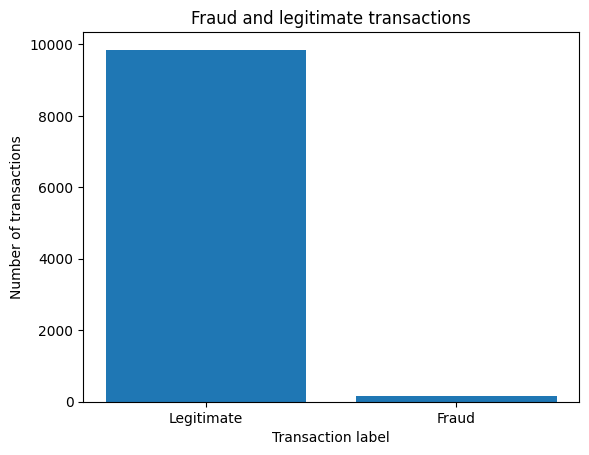

In [22]:
fraud_counts = df["is_fraud"].value_counts().sort_index()
print(fraud_counts)
print("Overall fraud rate (%):", round(df["is_fraud"].mean() * 100, 2))
plt.bar(["Legitimate", "Fraud"], [fraud_counts[0], fraud_counts[1]])
plt.title("Fraud and legitimate transactions")
plt.xlabel("Transaction label")
plt.ylabel("Number of transactions")
plt.show()

**Observation:** 151 fraud records and 9,849 legitimate records are present among 10,000 transactions. This is a **class imbalance**, so comparing group fraud *rates* is more informative than comparing fraud counts alone.

### 5.2 Fraud rates by merchant category

                   count  sum  fraud_rate
merchant_category                        
Clothing            2050   24    1.170732
Electronics         1923   24    1.248050
Food                2093   35    1.672241
Grocery             1944   39    2.006173
Travel              1990   29    1.457286


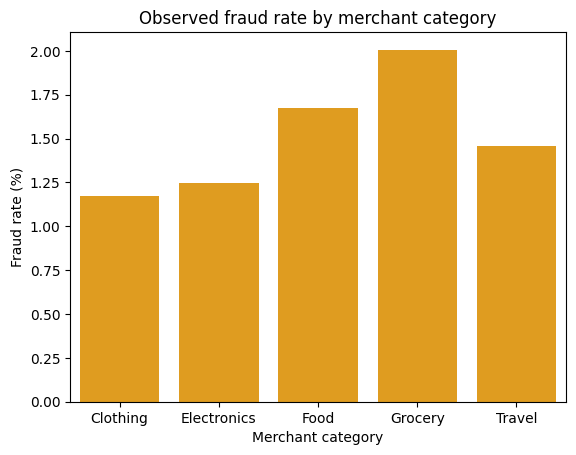

In [39]:
merchant = df.groupby("merchant_category")["is_fraud"].agg(["count", "sum"])
merchant["fraud_rate"] = 100 * merchant["sum"] / merchant["count"]
print(merchant)

sns.barplot(x=merchant.index, y=merchant["fraud_rate"],color='orange')
plt.title("Observed fraud rate by merchant category")
plt.xlabel("Merchant category")
plt.ylabel("Fraud rate (%)")
plt.show()

**Observation:** Compare group size and fraud rate side by side. In this file, **Grocery** has 39 fraud transactions among 1,944 (about 2.01%).

### 5.3 Fraud rates by transaction hour

                  count  sum  fraud_rate
transaction_hour                        
0                   417   37    8.872902
1                   425   34    8.000000
2                   385   23    5.974026
3                   425   27    6.352941
4                   384    1    0.260417
5                   419    2    0.477327
6                   413    2    0.484262
7                   425    0    0.000000
8                   424    3    0.707547
9                   426    1    0.234742
10                  358    1    0.279330
11                  385    2    0.519481
12                  417    0    0.000000
13                  420    2    0.476190
14                  458    1    0.218341
15                  432    2    0.462963
16                  421    0    0.000000
17                  429    2    0.466200
18                  439    1    0.227790
19                  421    4    0.950119
20                  419    2    0.477327
21                  423    1    0.236407
22              

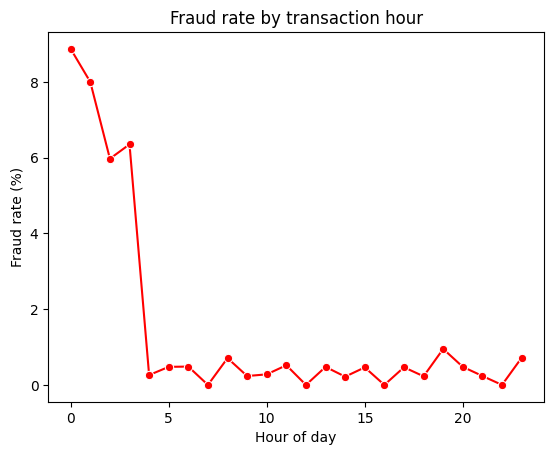

In [24]:
hour = df.groupby("transaction_hour")["is_fraud"].agg(["count", "sum"])
hour["fraud_rate"] = 100 * hour["sum"] / hour["count"]
print(hour)

sns.lineplot(x=hour.index, y=hour["fraud_rate"], marker="o", color="red")
plt.title("Fraud rate by transaction hour")
plt.xlabel("Hour of day")
plt.ylabel("Fraud rate (%)")
plt.show()

**Observation:** The dataset shows more fraud-labeled records at some early hours. Always check the number of transactions in each hour before interpreting a large rate.

### 5.4 Foreign transaction and location mismatch

Foreign transaction (0 = No, 1 = Yes):
                     count  sum  fraud_rate
foreign_transaction                        
0                     9022   69    0.764797
1                      978   82    8.384458


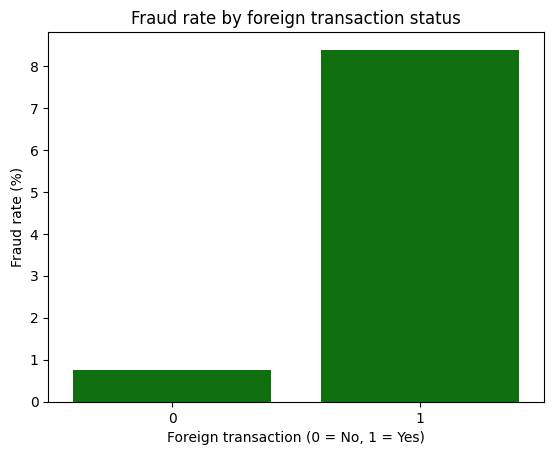

In [40]:
foreign = df.groupby("foreign_transaction")["is_fraud"].agg(["count", "sum"])
foreign["fraud_rate"] = 100 * foreign["sum"] / foreign["count"]
print("Foreign transaction (0 = No, 1 = Yes):")
print(foreign)

sns.barplot(x=foreign.index, y=foreign["fraud_rate"], color="green")
plt.title("Fraud rate by foreign transaction status")
plt.xlabel("Foreign transaction (0 = No, 1 = Yes)")
plt.ylabel("Fraud rate (%)")
plt.show()

Location mismatch (0 = No, 1 = Yes):
                   count  sum  fraud_rate
location_mismatch                        
0                   9143   79    0.864049
1                    857   72    8.401400


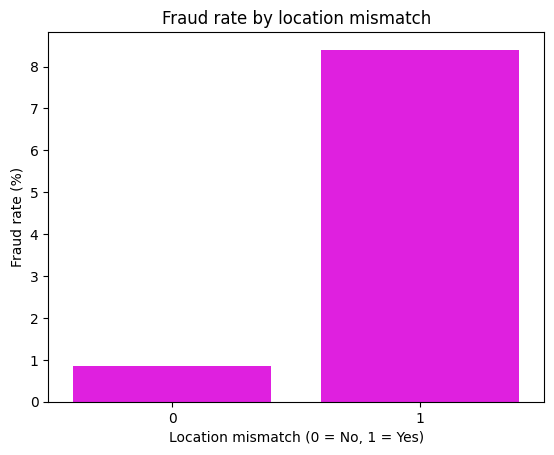

In [42]:
location = df.groupby("location_mismatch")["is_fraud"].agg(["count", "sum"])
location["fraud_rate"] = 100 * location["sum"] / location["count"]
print("Location mismatch (0 = No, 1 = Yes):")
print(location)

sns.barplot(x=location.index, y=location["fraud_rate"], color="magenta")
plt.title("Fraud rate by location mismatch")
plt.xlabel("Location mismatch (0 = No, 1 = Yes)")
plt.ylabel("Fraud rate (%)")
plt.show()

**Observation:** Fraud appears in 82 of 978 flagged foreign transactions (8.38%) and in 72 of 857 location-mismatch transactions (8.40%). The two comparisons overlap; they are not four distinct transaction types.

### 5.5 Transaction amount: histogram and box plot
Both plots were covered in the Matplotlib and Seaborn lectures.

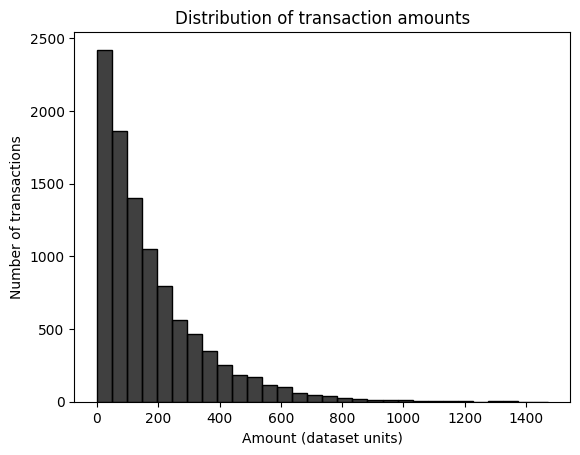

In [43]:
sns.histplot(data=df, x="amount", bins=30, color="black")
plt.title("Distribution of transaction amounts")
plt.xlabel("Amount (dataset units)")
plt.ylabel("Number of transactions")
plt.show()

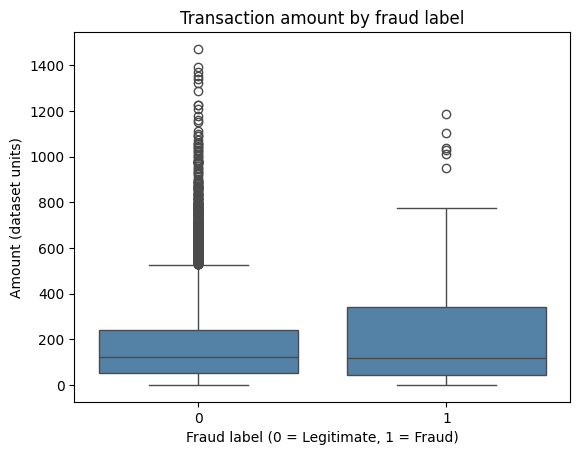

In [28]:
sns.boxplot(data=df, x="is_fraud", y="amount", color="steelblue")
plt.title("Transaction amount by fraud label")
plt.xlabel("Fraud label (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Amount (dataset units)")
plt.show()

**Observation:** The distributions overlap. Large values were **not** removed using IQR because they might represent real transactions in this synthetic dataset. We do not claim that a large transaction automatically indicates fraud.

### 5.6 Amount groups using `pd.cut()`
This is **binning**, directly covered in the Data Transformation slides. The original `amount` column is unchanged; a **new** analysis column is added.

              count  sum  fraud_rate
amount_group                        
0-50           2472   43    1.739482
50-200         4341   54    1.243953
200-500        2576   38    1.475155
500-2000        611   16    2.618658


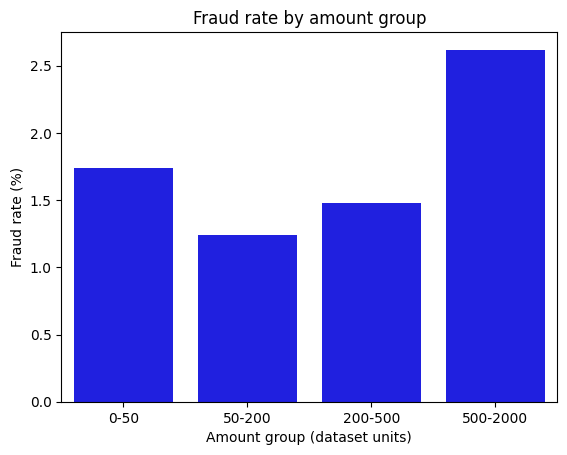

In [44]:
df["amount_group"] = pd.cut(
    df["amount"], bins=[0, 50, 200, 500, 2000],
    labels=["0-50", "50-200", "200-500", "500-2000"], include_lowest=True
)
amount_groups = df.groupby("amount_group", observed=True)["is_fraud"].agg(["count", "sum"])
amount_groups["fraud_rate"] = 100 * amount_groups["sum"] / amount_groups["count"]
print(amount_groups)

sns.barplot(x=amount_groups.index, y=amount_groups["fraud_rate"], color="blue")
plt.title("Fraud rate by amount group")
plt.xlabel("Amount group (dataset units)")
plt.ylabel("Fraud rate (%)")
plt.show()

**Observation:** Amount groups help compare rates without interpreting every individual amount. The chosen boundaries are for descriptive grouping, not a fraud-detection rule.

### 5.7 Device trust score and recent transaction frequency

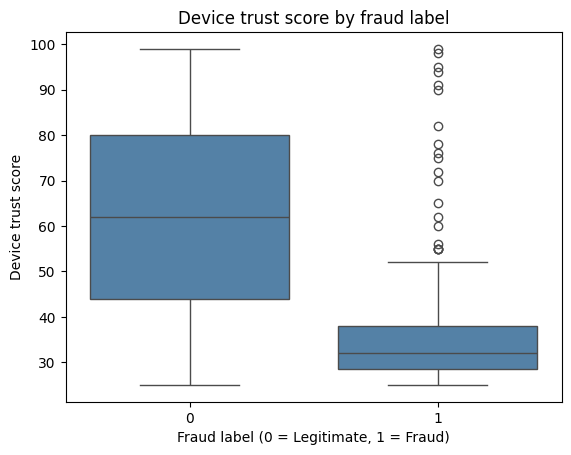

Average device trust by label:
is_fraud
0    62.165804
1    37.867550
Name: device_trust_score, dtype: float64


In [30]:
sns.boxplot(data=df, x="is_fraud", y="device_trust_score", color="steelblue")
plt.title("Device trust score by fraud label")
plt.xlabel("Fraud label (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Device trust score")
plt.show()

print("Average device trust by label:")
print(df.groupby("is_fraud")["device_trust_score"].mean())

                   count  sum  fraud_rate
velocity_last_24h                        
0                   1378   14    1.015965
1                   2694   21    0.779510
2                   2662   28    1.051841
3                   1785   21    1.176471
4                    934   10    1.070664
5                    365   42   11.506849
6                    131   11    8.396947
7                     42    4    9.523810
8                      6    0    0.000000
9                      3    0    0.000000


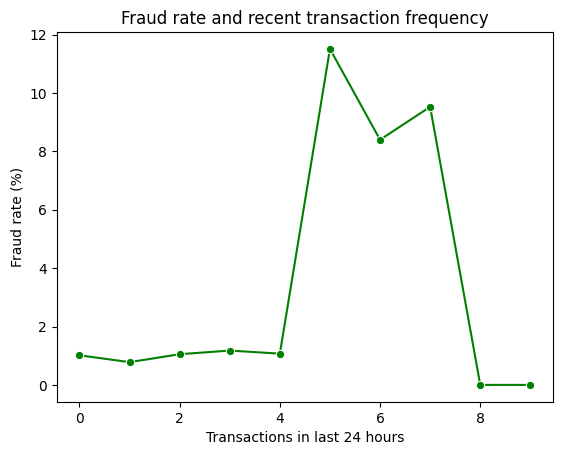

In [45]:
velocity = df.groupby("velocity_last_24h")["is_fraud"].agg(["count", "sum"])
velocity["fraud_rate"] = 100 * velocity["sum"] / velocity["count"]
print(velocity)

sns.lineplot(x=velocity.index, y=velocity["fraud_rate"], marker="o", color="green")
plt.title("Fraud rate and recent transaction frequency")
plt.xlabel("Transactions in last 24 hours")
plt.ylabel("Fraud rate (%)")
plt.show()

**Observation:** In the dataset, fraud-labeled records have a lower average device trust score and higher average recent transaction count. These are **associations**, not proof of causes.

### 5.8 Age groups using `pd.cut()`

           count  sum  fraud_rate
age_group                        
18-29       2315   32    1.382289
30-44       2876   49    1.703755
45-59       2893   45    1.555479
60+         1916   25    1.304802


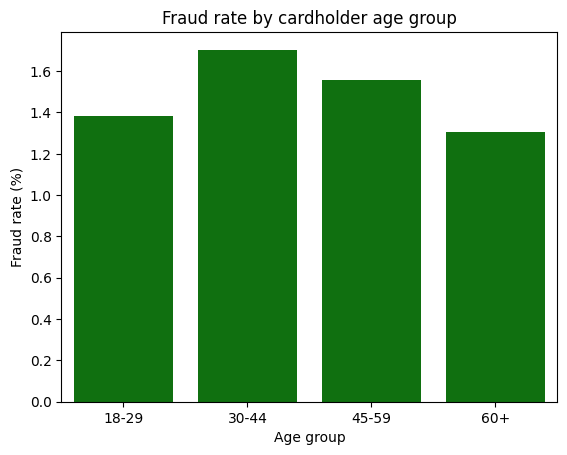

In [46]:
df["age_group"] = pd.cut(
    df["cardholder_age"], bins=[17, 29, 44, 59, 100],
    labels=["18-29", "30-44", "45-59", "60+"]
)
age = df.groupby("age_group", observed=True)["is_fraud"].agg(["count", "sum"])
age["fraud_rate"] = 100 * age["sum"] / age["count"]
print(age)

sns.barplot(x=age.index, y=age["fraud_rate"], color="green")
plt.title("Fraud rate by cardholder age group")
plt.xlabel("Age group")
plt.ylabel("Fraud rate (%)")
plt.show()

**Observation:** Look at the group sizes before concluding that a particular age group is more associated with fraud. Age alone is not sufficient to explain fraud patterns.

### 5.9 Correlation heatmap
`corr()` and `sns.heatmap()` are shown in the Seaborn slides. We exclude `transaction_id` because it is an ID, not a measurement.

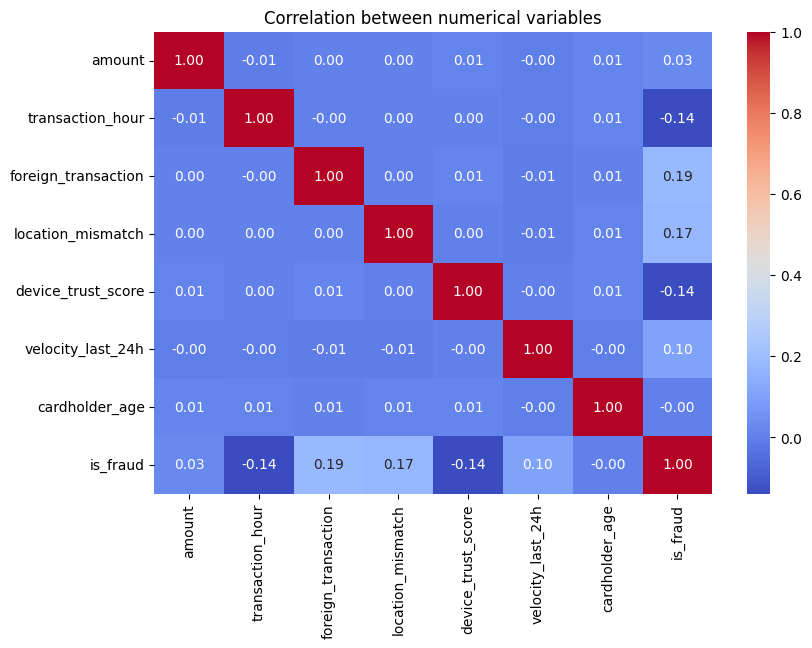

In [33]:
numeric_columns = ["amount", "transaction_hour", "foreign_transaction",
                   "location_mismatch", "device_trust_score",
                   "velocity_last_24h", "cardholder_age", "is_fraud"]
correlations = df[numeric_columns].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(correlations, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between numerical variables")
plt.show()

**Observation:** Correlation measures a relationship between numerical columns; it does **not** prove that a variable causes fraud. Binary flag columns are coded 0 or 1.

## 6. Conclusions and reflections

1. Out of **10,000 transactions**, **151 (1.51%)** are labeled as fraudulent. The data are strongly imbalanced.
2. The **foreign transaction** and **location mismatch** flags have higher observed fraud rates in this dataset than their unflagged groups.
3. Device trust score and recent transaction frequency differ between fraudulent and legitimate groups.
4. Transaction amounts show a wide spread. Possible outliers were examined and **kept** rather than deleted without a reason.
5. Group tables include counts so rates based on small groups are not overinterpreted.
6. The dataset is **synthetic**. We cannot infer real-world fraud rules or causal relationships from these observations.
7. We successfully demonstrated a **3NF relational SQLite database** and SQL queries **inside Jupyter Notebook**, as required.

**Limitations:** Synthetic data, no confirmed real fraud behavior, and no prediction or detection model (not part of the project objective).